In [3]:
import json
with open("nvdcve-2.0-2025.json", "r", encoding="utf-8") as f:
    nvd_data = json.load(f)
    print("Top-level keys in the JSON file:")
print(nvd_data.keys())

Top-level keys in the JSON file:
dict_keys(['resultsPerPage', 'startIndex', 'totalResults', 'format', 'version', 'timestamp', 'vulnerabilities'])


In [4]:
print("Total vulnerabilities in list:", len(nvd_data["vulnerabilities"]))

first_vuln = nvd_data["vulnerabilities"][0]

print("\nKeys inside a single vulnerability entry:")
print(first_vuln.keys())

Total vulnerabilities in list: 45428

Keys inside a single vulnerability entry:
dict_keys(['cve'])


In [5]:
cve_details = first_vuln["cve"]

print("Keys inside the 'cve' dictionary:")
print(cve_details.keys())

print("\nExample CVE ID:", cve_details.get("id"))
print("Published Date:", cve_details.get("published"))

Keys inside the 'cve' dictionary:
dict_keys(['id', 'sourceIdentifier', 'published', 'lastModified', 'vulnStatus', 'cveTags', 'descriptions', 'affected', 'metrics', 'weaknesses', 'configurations', 'references'])

Example CVE ID: CVE-2025-0168
Published Date: 2025-01-01T14:15:23.590


In [6]:
import pandas as pd

parsed_vulnerabilities = []

for item in nvd_data.get("vulnerabilities", []):
    cve = item.get("cve", {})
    
    cve_id = cve.get("id")
    published = cve.get("published")
    
    parsed_vulnerabilities.append({
        "cve_id": cve_id,
        "published_date": published
    })

df_cve = pd.DataFrame(parsed_vulnerabilities)

print(df_cve.head())
print("\nDataFrame Shape (Rows, Columns):", df_cve.shape)

           cve_id           published_date
0   CVE-2025-0168  2025-01-01T14:15:23.590
1  CVE-2025-22214  2025-01-02T04:15:06.277
2   CVE-2025-0171  2025-01-02T15:15:25.550
3   CVE-2025-0172  2025-01-02T16:15:09.103
4   CVE-2025-0173  2025-01-02T18:15:21.630

DataFrame Shape (Rows, Columns): (45428, 2)


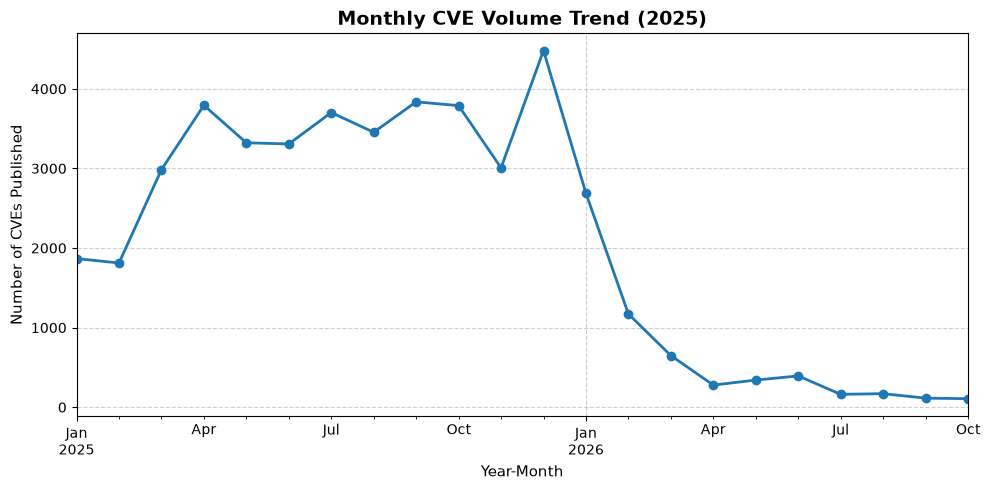

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Convert 'published_date' string to a proper pandas datetime object
df_cve["published_date"] = pd.to_datetime(df_cve["published_date"])

# Step 2: Extract Year-Month into a new column for trend analysis
df_cve["year_month"] = df_cve["published_date"].dt.to_period("M")

# Step 3: Count how many CVEs were published each month
monthly_counts = df_cve["year_month"].value_counts().sort_index()

# Step 4: Plot the monthly CVE volume trend
fig, ax = plt.subplots(figsize=(10, 5))
monthly_counts.plot(kind="line", ax=ax, marker="o", color="#1f77b4", linewidth=2)

ax.set_title("Monthly CVE Volume Trend (2025)", fontsize=14, fontweight="bold")
ax.set_xlabel("Year-Month", fontsize=11)
ax.set_ylabel("Number of CVEs Published", fontsize=11)
ax.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

# Step 5: Export chart at 300 DPI as required by professional pipelines
fig.savefig("monthly_cve_trend.png", dpi=300)
plt.show()

In [11]:
# Save our cleaned DataFrame to an Excel file
df_cve.to_excel("nvd_cleaned_data.xlsx", index=False)

print("Successfully saved your clean data to 'nvd_cleaned_data.xlsx'!")

Successfully saved your clean data to 'nvd_cleaned_data.xlsx'!


In [16]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH

# Step 1: Initialize a new Word Document
doc = Document()

# Set standard professional page margins (1 inch all around)
for section in doc.sections:
    section.top_margin = Inches(1)
    section.bottom_margin = Inches(1)
    section.left_margin = Inches(1)
    section.right_margin = Inches(1)

# Step 2: Add a styled professional title and subtitle
title_para = doc.add_paragraph()
title_para.alignment = WD_ALIGN_PARAGRAPH.CENTER
title_run = title_para.add_run("NVD Vulnerability Intelligence Report")
title_run.font.size = Pt(22)
title_run.font.bold = True
title_run.font.color.rgb = RGBColor(0x1F, 0x4E, 0x78)  # Professional Navy

subtitle_para = doc.add_paragraph()
subtitle_para.alignment = WD_ALIGN_PARAGRAPH.CENTER
sub_run = subtitle_para.add_run("Automated Security Analysis & Threat Trend Overview (2025)")
sub_run.font.size = Pt(11)
sub_run.font.italic = True
sub_run.font.color.rgb = RGBColor(0x59, 0x59, 0x59)  # Slate Gray

doc.add_paragraph()  # Add spacing

# Step 3: Executive Summary Section
doc.add_heading("1. Executive Summary", level=1)
doc.add_paragraph(
    "This automated report provides a high-level quantitative and visual summary of security "
    "vulnerabilities ingested, parsed, and processed directly from the NIST National Vulnerability "
    "Database (NVD) dataset. It is designed to offer stakeholders immediate insight into threat volumes "
    "and temporal distribution patterns."
)

# Step 4: Structured Key Metrics Table
doc.add_heading("2. Pipeline & Dataset Metrics", level=1)
doc.add_paragraph("The table below details core execution metrics captured during the data pipeline run:")

table = doc.add_table(rows=3, cols=2)
table.style = 'Table Grid'

# Populate table header
hdr_cells = table.rows[0].cells
hdr_cells[0].text = "Metric Parameter"
hdr_cells[1].text = "Recorded Value"
for cell in hdr_cells:
    for paragraph in cell.paragraphs:
        for run in paragraph.runs:
            run.font.bold = True

# Populate table rows
row_1 = table.rows[1].cells
row_1[0].text = "Total Vulnerabilities Ingested"
row_1[1].text = f"{len(df_cve):,}"

row_2 = table.rows[2].cells
row_2[0].text = "Source Dataset File"
row_2[1].text = "nvdcve-2.0-2025.json"

doc.add_paragraph()  # Add spacing

# Step 5: Embed the High-Resolution Trend Chart
doc.add_heading("3. Monthly Threat Volume Trend", level=1)
doc.add_paragraph(
    "The high-resolution visualization below charts the monthly publication volume of CVEs, "
    "highlighting critical activity spikes and baseline publishing trends throughout the period:"
)
doc.add_picture("monthly_cve_trend.png", width=Inches(6.0))

# Step 6: Save the polished document
doc.save("nvd_report.docx")
print("Successfully generated and saved your polished executive report to 'nvd_report.docx'!")

Successfully generated and saved your polished executive report to 'nvd_report.docx'!


In [18]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH

# Step 1: Initialize Document
doc = Document()

# Set Standard 1-inch Margins
for section in doc.sections:
    section.top_margin = Inches(1)
    section.bottom_margin = Inches(1)
    section.left_margin = Inches(1)
    section.right_margin = Inches(1)

# Step 2: Document Header
title_para = doc.add_paragraph()
title_para.alignment = WD_ALIGN_PARAGRAPH.CENTER
title_run = title_para.add_run("Project Documentation: Aegis NVD Pipeline")
title_run.font.size = Pt(22)
title_run.font.bold = True
title_run.font.color.rgb = RGBColor(0x1F, 0x4E, 0x78)

sub_para = doc.add_paragraph()
sub_para.alignment = WD_ALIGN_PARAGRAPH.CENTER
sub_run = sub_para.add_run("Automated Vulnerability Data Parsing, Analytics & Reporting Workflow")
sub_run.font.size = Pt(11)
sub_run.font.italic = True
sub_run.font.color.rgb = RGBColor(0x59, 0x59, 0x59)

doc.add_paragraph()

# Section 1: Project Overview
doc.add_heading("1. Project Overview", level=1)
doc.add_paragraph(
    "This project implements an automated end-to-end data analytics pipeline designed to process "
    "cybersecurity vulnerability data from the National Vulnerability Database (NVD). The pipeline ingests "
    "raw JSON datasets, cleans and structures time-series metrics, generates high-resolution trend visualizations, "
    "and outputs tabular exports alongside executive reporting deliverables."
)

# Section 2: Technical Stack
doc.add_heading("2. Technical Environment & Libraries", level=1)
doc.add_paragraph("• Environment: JupyterLab / Python 3")
doc.add_paragraph("• Data Ingestion & Transformation: Pandas, JSON module")
doc.add_paragraph("• Visualization & Graphics: Matplotlib (300 DPI Export)")
doc.add_paragraph("• Automated Reporting: python-docx, OpenPyXL")

# Section 3: End-to-End Pipeline Workflow
doc.add_heading("3. Data Pipeline Workflow", level=1)

doc.add_heading("3.1 Ingestion & Parsing", level=2)
doc.add_paragraph(
    "The raw NIST dataset (nvdcve-2.0-2025.json) containing 45,428 JSON vulnerability records is loaded into memory. "
    "Target attributes (cve_id and published_date) are extracted from nested dictionary nodes into a flat tabular format."
)

doc.add_heading("3.2 Data Cleaning & Time-Series Extraction", level=2)
doc.add_paragraph(
    "String timestamps are converted into native pandas datetime objects. A dedicated Year-Month period column "
    "is generated to support temporal grouping and vulnerability publication rate analysis."
)

doc.add_heading("3.3 Data Persistence & Visualization", level=2)
doc.add_paragraph(
    "The structured DataFrame is exported to Excel (nvd_cleaned_data.xlsx). Aggregated monthly counts are plotted "
    "using Matplotlib and saved as a high-resolution 300 DPI image asset (monthly_cve_trend.png)."
)

doc.add_heading("3.4 Executive Report Automation", level=2)
doc.add_paragraph(
    "Using python-docx, an executive Word document (nvd_report.docx) is dynamically assembled with custom formatting, "
    "summary statistics tables, and embedded chart visuals."
)

# Section 4: Key Artifacts Summary
doc.add_heading("4. Generated Project Deliverables", level=1)

# FIXED: rows=6 to account for 1 header row + 5 data rows
table = doc.add_table(rows=6, cols=2)
table.style = 'Table Grid'

headers = table.rows[0].cells
headers[0].text = "Artifact File"
headers[1].text = "Role in Pipeline"
for cell in headers:
    for p in cell.paragraphs:
        for run in p.runs:
            run.font.bold = True

artifacts = [
    ("nvdcve-2.0-2025.json", "Raw source data ingested directly from NIST NVD"),
    ("NVD_Analysis.ipynb", "Primary notebook containing execution code and analytics workflow"),
    ("nvd_cleaned_data.xlsx", "Structured tabular dataset export for spreadsheet/SQL usage"),
    ("monthly_cve_trend.png", "300 DPI high-resolution line chart visualization asset"),
    ("nvd_report.docx", "Automated executive report containing summary stats and embedded visual")
]

for idx, (filename, desc) in enumerate(artifacts, start=1):
    row_cells = table.rows[idx].cells
    row_cells[0].text = filename
    row_cells[1].text = desc

# Save documentation
doc.save("project_documentation.docx")
print("Successfully generated project documentation as 'project_documentation.docx'!")

Successfully generated project documentation as 'project_documentation.docx'!
